# Volve: анатомия месторождения
#
Разведочный анализ данных реального морского месторождения **Volve** (Equinor,
Северное море, 2008–2016). Данные открыты Equinor для исследований.
#
**Чем отличается от шаблонного EDA:** анализ построен не на «посмотрим на
распределение», а на вопросах к месторождению — каждый раздел проверяет
конкретную гипотезу статистически (тесты, доверительные интервалы, бутстреп),
а заканчивается выводами, пригодными для принятия решений по разработке.
#
Данные: суточная добыча 7 скважин основного фонда (5 добывающих, 2
нагнетательные; F-1 C переведена из добычи в нагнетание), 15 634 записи.
#
Источник: Equinor Volve field data, Equinor Open Data Licence
(https://www.equinor.com/energy/volve-data-sharing). Правообладатели — Equinor ASA и бывшие
партнёры по лицензии Volve.

## 1. Знакомство с данными

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
RNG = np.random.default_rng(42)

df = pd.read_csv("data/daily.csv", parse_dates=["DATEPRD"])
df["WELL_BORE_CODE"] = df["WELL_BORE_CODE"].str.strip()
df["WELL"] = df["WELL_BORE_CODE"].str.replace("NO 15/9-", "", regex=False)
print(f"строк: {len(df):,}, скважин: {df['WELL'].nunique()}, "
      f"период: {df['DATEPRD'].min().date()} — {df['DATEPRD'].max().date()}")
df.head(3)

строк: 15,634, скважин: 7, период: 2007-09-01 — 2016-12-01


,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE,WELL
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,production,WI,F-1 C
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,production,OP,F-1 C
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,production,OP,F-1 C


In [2]:
# Типы скважин и судьба F-1 C: скважина сменила роль во время разработки
type_days = (df.groupby(["WELL", "WELL_TYPE"])["DATEPRD"]
               .agg(["min", "max", "count"]))
type_days

min        max  count
WELL   WELL_TYPE                             
F-1 C  OP        2014-04-08 2016-04-21    744
       WI        2014-04-07 2014-07-07      2
F-11 H OP        2013-07-08 2016-09-17   1165
F-12 H OP        2008-02-12 2016-09-17   3056
F-14 H OP        2008-02-12 2016-09-17   3056
F-15 D OP        2014-01-12 2016-09-17    978
F-4 AH WI        2007-09-01 2016-12-01   3327
F-5 AH OP        2016-04-12 2016-09-17    144
       WI        2007-09-01 2016-09-18   3162

In [3]:
# F-1 C: когда произошёл перевод из добычи в нагнетание?
f1 = df[df["WELL"] == "F-1 C"].sort_values("DATEPRD")
switch = f1.loc[f1["WELL_TYPE"].ne(f1["WELL_TYPE"].shift()), ["DATEPRD", "WELL_TYPE"]]
switch

,DATEPRD,WELL_TYPE
0,2014-04-07,WI
1,2014-04-08,OP
91,2014-07-07,WI
92,2014-07-08,OP


## 2. Качество данных — главный раздел настоящего EDA
#
Проверяем: пропуски по колонкам, дни с нулевой наработкой, дубликаты
«скважина-дата», корректность объёмов. Каждый дефект дальше либо
обрабатывается, либо становится флагом.

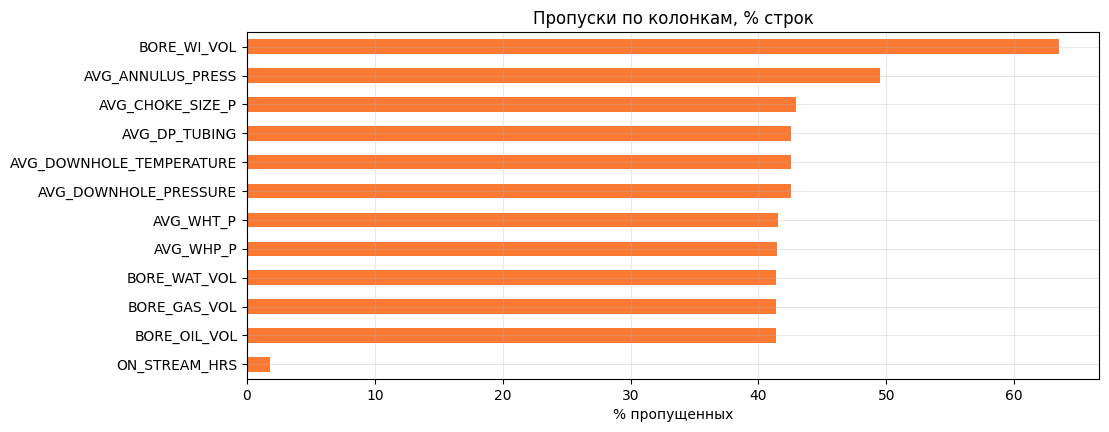

In [4]:
# 2.1. Пропуски по рабочим колонкам (служебные NPD_* исключаем)
work_cols = ["ON_STREAM_HRS", "AVG_DOWNHOLE_PRESSURE", "AVG_DOWNHOLE_TEMPERATURE",
             "AVG_DP_TUBING", "AVG_ANNULUS_PRESS", "AVG_CHOKE_SIZE_P",
             "AVG_WHP_P", "AVG_WHT_P", "BORE_OIL_VOL", "BORE_GAS_VOL",
             "BORE_WAT_VOL", "BORE_WI_VOL"]
miss = df[work_cols].isna().mean().mul(100).sort_values()
ax = miss.plot.barh(color="#fa7a33")
ax.set_title("Пропуски по колонкам, % строк")
ax.set_xlabel("% пропущенных")
plt.show()

In [5]:
# 2.2. Дубликаты «скважина-дата» и отрицательные объёмы
dup = df.duplicated(subset=["WELL", "DATEPRD"]).sum()
neg = (df[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]] < 0).sum()
print(f"дубликатов скважина-дата: {dup}")
print(f"отрицательных объёмов:\n{neg}")

дубликатов скважина-дата: 0
отрицательных объёмов:
BORE_OIL_VOL    0
BORE_GAS_VOL    0
BORE_WAT_VOL    4
BORE_WI_VOL     0
dtype: int64


In [6]:
# 2.3. Дни с нулевой наработкой — остановки: сколько их и у кого
df["shutdown"] = df["ON_STREAM_HRS"].fillna(0) == 0
sh = (df.groupby("WELL")["shutdown"].agg(["sum", "mean"])
        .rename(columns={"sum": "дней остановок", "mean": "доля, %"}))
sh["доля, %"] = (sh["доля, %"] * 100).round(1)
sh.sort_values("доля, %", ascending=False)

,дней остановок,"доля, %"
WELL,,
F-1 C,308,41.3
F-15 D,209,21.4
F-5 AH,630,19.1
F-4 AH,497,14.9
F-14 H,332,10.9
F-12 H,218,7.1
F-11 H,43,3.7


## 3. Очистка: правила и их обоснование
#
1. Отрицательных объёмов и дубликатов нет — контроли пройдены.
2. Показания датчиков (AVG_*) на остановках не имеют физического смысла —
   остаются NaN, но не обнуляются.
3. Объёмы за день остановки считаем нулевой добычей (уже 0 в данных).
4. Дополнительно рассчитываем производные метрики: обводнённость (WC),
   дебит жидкости и накопленные объёмы.

In [7]:
d = df.copy()
for c in ["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]:
    d[c] = d[c].fillna(0.0)
d["qliq"] = d["BORE_OIL_VOL"] + d["BORE_WAT_VOL"]
d["wc"] = d["BORE_WAT_VOL"] / d["qliq"].replace(0, np.nan)
d = d.sort_values(["WELL", "DATEPRD"])
d[["cum_oil", "cum_wat", "cum_inj"]] = d.groupby("WELL")[["BORE_OIL_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].cumsum()
d.head(3)[["DATEPRD", "WELL", "BORE_OIL_VOL", "qliq", "wc", "cum_oil"]]

,DATEPRD,WELL,BORE_OIL_VOL,qliq,wc,cum_oil
0,2014-04-07,F-1 C,0.0,0.0,NaN,0.0
1,2014-04-08,F-1 C,0.0,0.0,NaN,0.0
2,2014-04-09,F-1 C,0.0,0.0,NaN,0.0


## 4. Месторождение целиком: профиль добычи и ключевые события

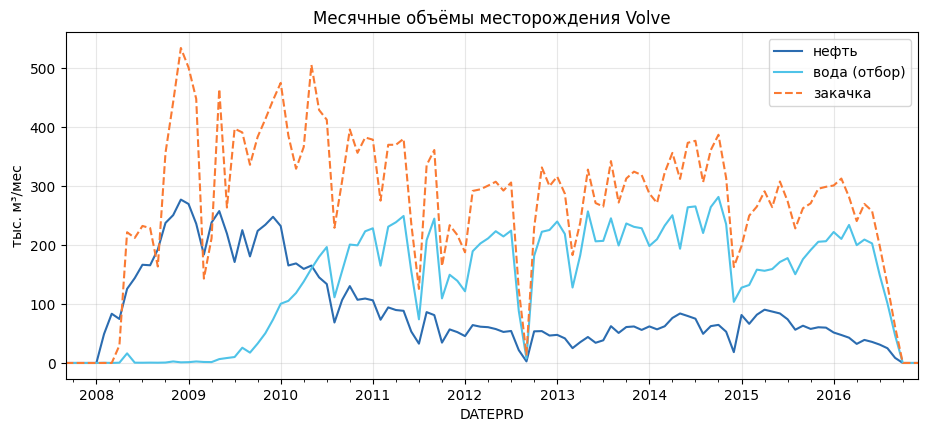

In [8]:
field = d.set_index("DATEPRD").resample("MS")[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].sum() / 1e3
ax = field[["BORE_OIL_VOL", "BORE_WAT_VOL"]].plot(color=["#2b6cb0", "#4fc3e8"])
field["BORE_WI_VOL"].plot(ax=ax, color="#fa7a33", style="--")
ax.set_title("Месячные объёмы месторождения Volve")
ax.set_ylabel("тыс. м³/мес")
ax.legend(["нефть", "вода (отбор)", "закачка"])
plt.show()

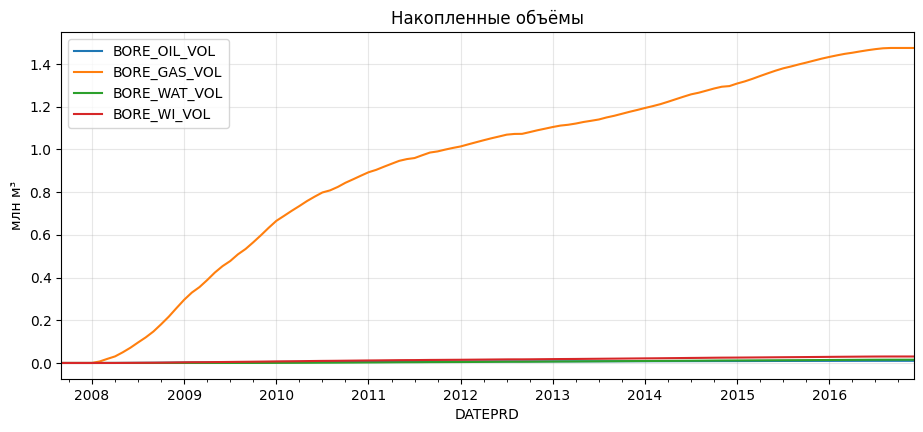

нефть, млн м³           10.04
газ, млн м³           1475.37
вода отбор, млн м³      15.32
закачка, млн м³         30.33
dtype: float64

In [9]:
ax = (field.cumsum() / 1e6).plot()
ax.set_title("Накопленные объёмы")
ax.set_ylabel("млн м³")
plt.show()
field_totals = (d[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].sum() / 1e6).round(2)
field_totals.rename(index={"BORE_OIL_VOL": "нефть, млн м³", "BORE_GAS_VOL": "газ, млн м³",
                           "BORE_WAT_VOL": "вода отбор, млн м³", "BORE_WI_VOL": "закачка, млн м³"})

## 5. Скважины: вклад, жизнь, карта

In [10]:
wells = (d.groupby("WELL")
           .agg(нефть_млн=("cum_oil", "max"), вода_млн=("cum_wat", "max"),
                закачка_млн=("cum_inj", "max"), дней=("DATEPRD", "count")))
wells["нефть_млн"] /= 1e6; wells["вода_млн"] /= 1e6; wells["закачка_млн"] /= 1e6
wells.round(2).sort_values("нефть_млн", ascending=False)

,нефть_млн,вода_млн,закачка_млн,дней
WELL,,,,
F-12 H,4.58,6.83,0.00,3056
F-14 H,3.94,7.12,0.00,3056
F-11 H,1.15,1.09,0.00,1165
F-1 C,0.18,0.21,0.00,746
F-15 D,0.15,0.05,0.00,978
F-5 AH,0.04,0.01,14.09,3306
F-4 AH,0.00,0.00,16.24,3327


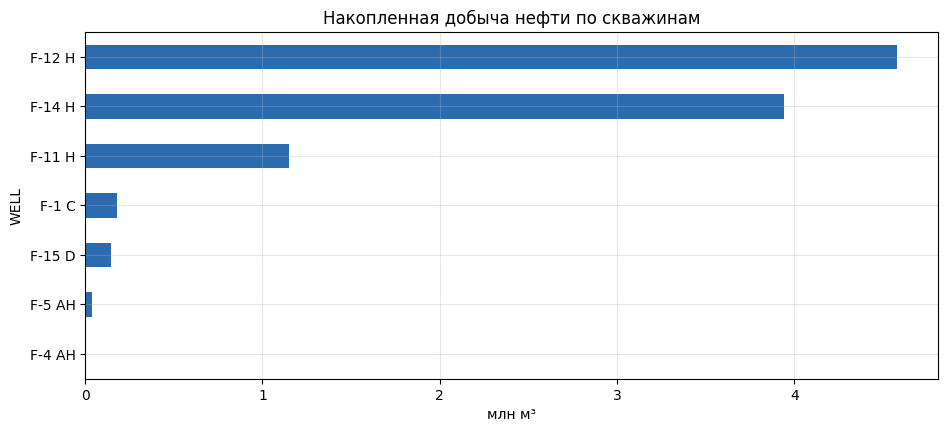

In [11]:
ax = wells["нефть_млн"].sort_values().plot.barh(color="#2b6cb0")
ax.set_title("Накопленная добыча нефти по скважинам")
ax.set_xlabel("млн м³")
plt.show()

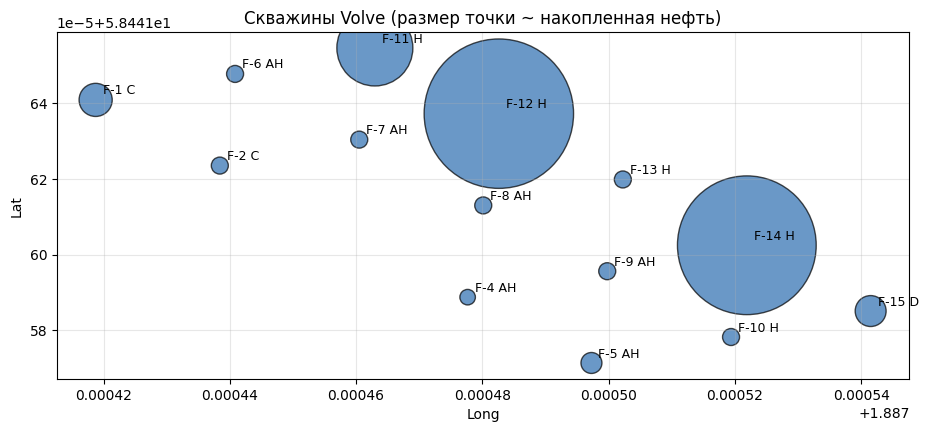

In [12]:
# Мини-карта: где сидят скважины (размер точки — накопленная нефть)
loc = pd.read_csv("data/locations.csv")
loc["WELL"] = loc["WELL_BORE_CODE"].str.strip().str.replace("NO 15/9-", "", regex=False)
m = loc.merge(wells.reset_index(), on="WELL", how="left")
ax = m.plot.scatter(x="Long", y="Lat", s=(m["нефть_млн"].fillna(0.01) + 0.05) * 2500,
                    c="#2b6cb0", alpha=0.7, edgecolor="k")
for _, r in m.iterrows():
    ax.annotate(r["WELL"], (r["Long"], r["Lat"]), xytext=(5, 4),
                textcoords="offset points", fontsize=9)
ax.set_title("Скважины Volve (размер точки ~ накопленная нефть)")
plt.show()

## 6. Обводнённость: прорыв воды
#
**Гипотеза:** добывающие скважины показывают классическую картину прорыва
воды — WC растёт ступенчато; момент прорыва (первый день WC > 10 %)
различается по скважинам и связан с близостью к нагнетательным.

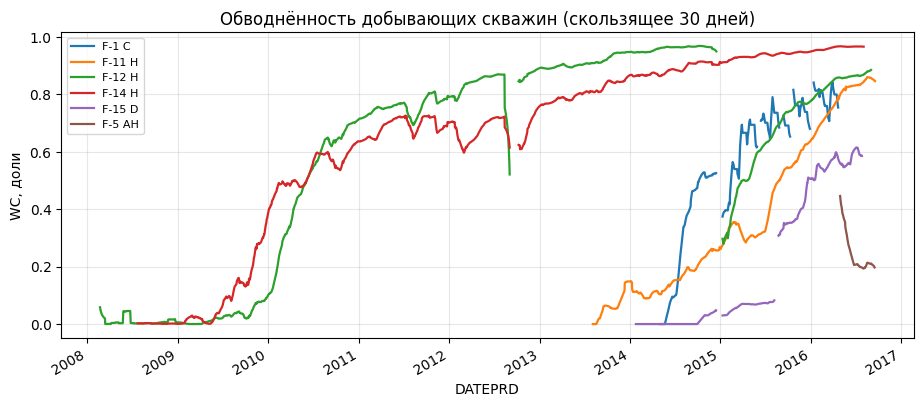

In [13]:
prod = d[d["WELL_TYPE"] == "OP"]
fig, ax = plt.subplots()
for w, g in prod.groupby("WELL"):
    g = g.set_index("DATEPRD")["wc"].rolling("30D", min_periods=10).mean()
    g.plot(ax=ax, label=w, lw=1.6)
ax.set_title("Обводнённость добывающих скважин (скользящее 30 дней)")
ax.set_ylabel("WC, доли")
ax.legend(fontsize=8)
plt.show()

In [14]:
bt = (prod[prod["wc"] > 0.10].groupby("WELL")["DATEPRD"].min()
        .dt.strftime("%Y-%m-%d").rename("прорыв (WC>10%)"))
first_oil = prod.groupby("WELL")["DATEPRD"].min().dt.strftime("%Y-%m-%d").rename("пуск")
pd.concat([first_oil, bt], axis=1)

,пуск,прорыв (WC>10%)
WELL,,
F-1 C,2014-04-08,2014-05-23
F-11 H,2013-07-08,2013-09-14
F-12 H,2008-02-12,2008-02-12
F-14 H,2008-02-12,2009-01-29
F-15 D,2014-01-12,2015-08-16
F-5 AH,2016-04-12,2016-04-20


## 7. Закачка против отбора: компенсация
#
**Гипотеза:** месячные закачка и отбор жидкости связаны (режим
заводнения), при этом связь с добычей воды сильнее, чем с нефтью.

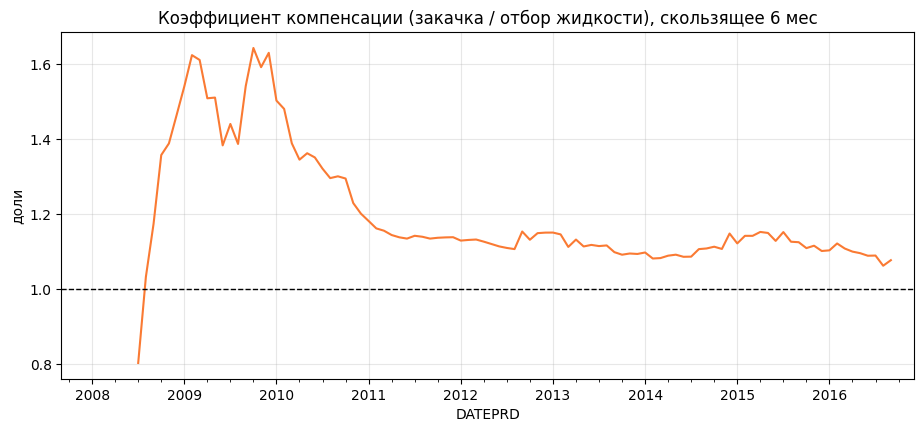

медианная компенсация: 1.12


In [15]:
fm = d.set_index("DATEPRD").resample("MS")[["BORE_OIL_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]].sum()
vrr = fm["BORE_WI_VOL"] / fm[["BORE_OIL_VOL", "BORE_WAT_VOL"]].sum(axis=1).replace(0, np.nan)
ax = vrr.rolling(6).mean().plot(color="#fa7a33")
ax.axhline(1.0, ls="--", c="k", lw=1)
ax.set_title("Коэффициент компенсации (закачка / отбор жидкости), скользящее 6 мес")
ax.set_ylabel("доли")
plt.show()
print(f"медианная компенсация: {vrr.median():.2f}")

## 8. Статистическая проверка гипотез
#
### H1. Падает ли дебит после остановки скважины (эффект перезапуска)
#
Утверждение из практики: после остановки дебит нефти восстанавливается не сразу.
Наивная проверка — сравнить средний дебит за 10 дней до остановки и 10 дней после.
Но у Volve дебит падает и без остановок (decline ~40 %/год, раздел H3): за три недели
между окнами «до» и «после» он снизился бы в любом случае. Поэтому три шага:
#
1. **наивное «до/после»** — как обычно делают;
2. **плацебо** — тот же расчёт в случайные дни без остановок: сколько «эффекта» даёт само падение;
3. **поправка на тренд** — прогноз дебита по тренду за 60 дней до остановки против факта после.
#
Эпизоды одной скважины не независимы, а скважин всего пять, поэтому интервал —
**бутстреп по скважинам** (кластерный), а не по эпизодам.

In [16]:
def shut_episodes(w):
    """Эпизоды остановок скважины: подряд идущие дни с нулевой наработкой."""
    days = df[(df["WELL"] == w) & df["shutdown"]]["DATEPRD"].sort_values()
    eps, cur = [], []
    for t in days:
        if cur and (t - cur[-1]).days <= 1:
            cur.append(t)
        else:
            if cur:
                eps.append((cur[0], cur[-1]))
            cur = [t]
    if cur:
        eps.append((cur[0], cur[-1]))
    return eps


def before_after(q, t0, t1):
    """Средний дебит за 10 дней до t0 и после t1 + прогноз по лог-тренду за 60 дней до t0."""
    pre = q.loc[t0 - pd.Timedelta(days=10):t0 - pd.Timedelta(days=1)]
    post = q.loc[t1 + pd.Timedelta(days=1):t1 + pd.Timedelta(days=10)]
    hist = q.loc[t0 - pd.Timedelta(days=60):t0 - pd.Timedelta(days=1)]
    hist = hist[hist > 0]
    if len(pre) < 7 or len(post) < 7 or len(hist) < 20 or pre.mean() <= 0:
        return None
    b = np.polyfit((hist.index - t0).days.values, np.log(hist.values), 1)
    pred = np.exp(np.polyval(b, (t1 - t0).days + 5.5))      # середина окна «после»
    return pre.mean(), post.mean(), pred


rows = []
for w, g in d[d["WELL_TYPE"] == "OP"].groupby("WELL"):
    q = g.set_index("DATEPRD").sort_index()["BORE_OIL_VOL"]
    shut = set(df[(df["WELL"] == w) & df["shutdown"]]["DATEPRD"])
    for t0, t1 in shut_episodes(w):
        r = before_after(q, t0, t1)
        if r:
            rows.append((w, "остановка", *r))
    # плацебо: рабочие дни, в ±12 дней от которых остановок не было
    ok_days = [t for t in q.index[q.values > 0]
               if not any(t + pd.Timedelta(days=k) in shut for k in range(-12, 13))]
    picked = RNG.choice(len(ok_days), min(len(ok_days), 300), replace=False)
    for i in sorted(picked):
        r = before_after(q, ok_days[i], ok_days[i])
        if r:
            rows.append((w, "плацебо", *r))
ep = pd.DataFrame(rows, columns=["WELL", "тип", "до", "после", "прогноз"])
ep = ep[ep["WELL"].isin(ep.loc[ep["тип"] == "остановка", "WELL"])]   # скважины, где были остановки
ep["наивно, %"] = np.log(ep["после"].clip(lower=1) / ep["до"].clip(lower=1)) * 100
ep["к тренду, %"] = np.log(ep["после"].clip(lower=1) / ep["прогноз"]) * 100
real = ep[ep["тип"] == "остановка"]
stat_h1, p_h1 = stats.wilcoxon(real["до"], real["после"])
print(f"эпизодов остановок: {len(real)}, плацебо-окон: {(ep['тип'] == 'плацебо').sum()}; "
      f"наивный Wilcoxon p = {p_h1:.3f}")
ep.groupby("тип")[["наивно, %", "к тренду, %"]].median().round(1)

эпизодов остановок: 111, плацебо-окон: 1306; наивный Wilcoxon p = 0.030


,"наивно, %","к тренду, %"
тип,,
остановка,-7.9,-3.1
плацебо,-2.7,0.6


In [17]:
# Эффект = (остановки − плацебо) по поправленному на тренд дебиту; бутстреп по скважинам.
# Медианы, а не средние: если скважину вскоре снова остановили, дебит в окне «после» близок
# к нулю, и одно такое окно уводит среднее логарифма на десятки процентов.
def h1_effect(sample):
    m = sample.groupby("тип")["к тренду, %"].median()
    return m.get("остановка", np.nan) - m.get("плацебо", np.nan)


wells_op = ep["WELL"].unique()
boot = [h1_effect(pd.concat([ep[ep["WELL"] == w] for w in RNG.choice(wells_op, len(wells_op))]))
        for _ in range(2000)]
h1_est = h1_effect(ep)
h1_lo, h1_hi = np.nanpercentile(boot, [2.5, 97.5])
by_well = ep.pivot_table(index="WELL", columns="тип", values="к тренду, %", aggfunc="median")
by_well["эффект"] = by_well["остановка"] - by_well["плацебо"]
by_well["эпизодов"] = real.groupby("WELL").size()
print(f"эффект остановки к тренду: {h1_est:+.1f} %, 95 % ДИ (бутстреп по скважинам) "
      f"[{h1_lo:+.1f}; {h1_hi:+.1f}] %")
by_well.round(1)

эффект остановки к тренду: -3.7 %, 95 % ДИ (бутстреп по скважинам) [-14.5; -0.1] %


тип,остановка,плацебо,эффект,эпизодов
WELL,,,,
F-1 C,-29.4,7.3,-36.6,19
F-11 H,-4.5,0.9,-5.4,10
F-12 H,-2.4,-0.8,-1.5,41
F-14 H,-1.3,-1.2,-0.1,30
F-15 D,7.8,1.3,6.5,11


**Итог H1.** Наивное «до/после» (медиана −8 %) примерно вдвое завышает эффект: плацебо-окна
без всяких остановок дают −2 % — это естественное падение добычи. С поправкой на тренд
остаётся около −4 % с интервалом от −15 % почти до нуля, и держится он на F-1 C — скважине
на исходе добычи, которую затем перевели под закачку. У F-12 H и F-14 H, дающих 85 % нефти,
эффект около нуля, у F-15 D — обратный. Пять скважин — мало для бутстрепа по скважинам, так что
интервал ориентировочный. **Вывод: остановка бьёт по слабым скважинам на поздней стадии,
а для основного фонда заметного эффекта перезапуска нет.**

### H2. Связь закачки с отбором (месячная шкала)
#
Сначала — как обычно: Spearman-корреляция месячных объёмов закачки с добычей воды и нефти
на лагах 0–6 месяцев.

In [18]:
lag_scan = []
for lag in range(0, 7):
    wi = fm["BORE_WI_VOL"].shift(lag)
    for name, target in [("вода", fm["BORE_WAT_VOL"]), ("нефть", fm["BORE_OIL_VOL"])]:
        ok = wi.notna() & target.notna()
        r, p = stats.spearmanr(wi[ok], target[ok])
        lag_scan.append((lag, name, r, p))
lag_tb = pd.DataFrame(lag_scan, columns=["лаг, мес", "целевая", "Spearman ρ", "p"])
lag_tb.pivot(index="лаг, мес", columns="целевая", values="Spearman ρ").round(2)

целевая,вода,нефть
"лаг, мес",,
0,0.46,0.65
1,0.32,0.43
2,0.20,0.31
3,0.21,0.31
4,0.20,0.22
5,0.19,0.18
6,0.21,0.14


Сильнее всего связь без лага, и с **нефтью** она сильнее, чем с водой. Для «отклика на
заводнение» это подозрительно, поэтому две проверки:
#
* **интервал.** Месячный ряд автокоррелирован, обычный бутстреп по месяцам делает интервал
  слишком узким — нужен блочный бутстреп (блоки по 6 месяцев);
* **общая причина.** Когда платформа стоит, падают и закачка, и добыча. Если связь держится
  на времени работы, то в дебитах на час работы она должна исчезнуть.

In [19]:
def block_boot(x, y, stat, n_boot=2000, block=6):
    n, out = len(x), []
    for _ in range(n_boot):
        starts = RNG.integers(0, n - block + 1, int(np.ceil(n / block)))
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        out.append(stat(x[idx], y[idx]))
    return np.percentile(out, [2.5, 97.5])


def spear(a, b):
    return stats.spearmanr(a, b)[0]


x, y = fm["BORE_WI_VOL"].values, fm["BORE_WAT_VOL"].values
rho_wat = spear(x, y)
iid = [spear(x[i], y[i]) for i in (RNG.integers(0, len(x), len(x)) for _ in range(2000))]
iid_lo, iid_hi = np.percentile(iid, [2.5, 97.5])
rho_lo, rho_hi = block_boot(x, y, spear)

# время работы: часы добывающих и нагнетательных скважин за месяц
hrs = (d.pivot_table(index=pd.Grouper(key="DATEPRD", freq="MS"), columns="WELL_TYPE",
                     values="ON_STREAM_HRS", aggfunc="sum").reindex(fm.index).fillna(0))
rate = pd.DataFrame({"закачка/ч": fm["BORE_WI_VOL"] / hrs["WI"].replace(0, np.nan),
                     "вода/ч": fm["BORE_WAT_VOL"] / hrs["OP"].replace(0, np.nan),
                     "нефть/ч": fm["BORE_OIL_VOL"] / hrs["OP"].replace(0, np.nan)}).diff().dropna()
vol = fm.diff().dropna()
rho_rate = spear(rate["закачка/ч"], rate["вода/ч"])
h2 = pd.DataFrame({
    "что коррелируем (изменение месяц к месяцу)": [
        "часы работы: добыча ~ закачка", "объёмы: закачка ~ вода", "объёмы: закачка ~ нефть",
        "дебит на час: закачка ~ вода", "дебит на час: закачка ~ нефть"],
    "Spearman ρ": [
        spear(hrs["OP"].diff().dropna(), hrs["WI"].diff().dropna()),
        spear(vol["BORE_WI_VOL"], vol["BORE_WAT_VOL"]), spear(vol["BORE_WI_VOL"], vol["BORE_OIL_VOL"]),
        rho_rate, spear(rate["закачка/ч"], rate["нефть/ч"])]})
print(f"уровни, лаг 0: ρ = {rho_wat:.2f}; 95 % ДИ: обычный бутстреп [{iid_lo:.2f}; {iid_hi:.2f}], "
      f"блочный [{rho_lo:.2f}; {rho_hi:.2f}]")
h2.round(2)

уровни, лаг 0: ρ = 0.46; 95 % ДИ: обычный бутстреп [0.26; 0.64], блочный [0.01; 0.76]


,что коррелируем (изменение месяц к месяцу),Spearman ρ
0,часы работы: добыча ~ закачка,0.75
1,объёмы: закачка ~ вода,0.73
2,объёмы: закачка ~ нефть,0.71
3,дебит на час: закачка ~ вода,0.13
4,дебит на час: закачка ~ нефть,0.01


**Итог H2.** Корреляция месячных объёмов почти целиком объясняется временем работы платформы:
часы добывающих и нагнетательных скважин меняются синхронно, а в дебитах на час работы связь
закачки с водой и нефтью почти исчезает. Блочный бутстреп к тому же расширяет интервал для
уровней до нуля. **Отклик добычи на заводнение по месячным суммам месторождения не виден** —
для этого нужен анализ пар «нагнетательная — добывающая» (например, ёмкостно-резистивная
модель, CRM) на суточных данных.

### H3. Темп падения добычи (экспоненциальный decline)
#
Для крупнейшей скважины F-12 H на участке после первого года работы оцениваем
экспоненциальный спад: ln(q) = a + b·t. Остатки месячного ряда автокоррелированы, поэтому
интервал наклона — с поправкой Ньюи — Уэста (HAC), а не обычный МНК.

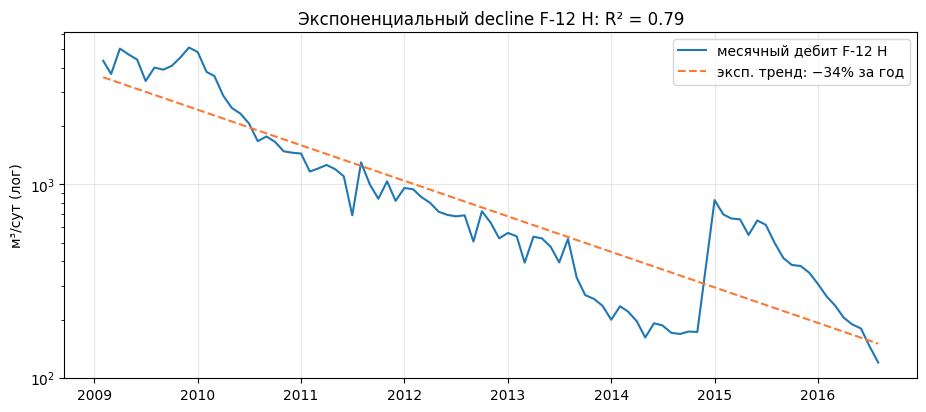

номинальный темп D = 42.3%/год → дебит за год падает на 34%; 95 % ДИ D: МНК [37.7%; 46.8%], HAC [31.7%; 52.9%]; Durbin — Watson = 0.26


In [20]:
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

g12 = (d[(d["WELL"] == "F-12 H") & (d["qliq"] > 0)]
       .set_index("DATEPRD").resample("MS")["BORE_OIL_VOL"].mean())
g12s = g12[(g12 > 0) & (g12.index >= g12.index[0] + pd.DateOffset(years=1))]
t = np.asarray((g12s.index - g12s.index[0]).days / 365.25)
X = sm.add_constant(t)
ols = sm.OLS(np.log(g12s.values), X).fit()
hac = sm.OLS(np.log(g12s.values), X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
D = -ols.params[1]
lo_ols, hi_ols = -ols.conf_int()[1][::-1]
lo, hi = -hac.conf_int()[1][::-1]
D_eff = 1 - np.exp(-D)
dw = durbin_watson(ols.resid)
fig, ax = plt.subplots()
ax.plot(g12s.index, g12s.values, label="месячный дебит F-12 H")
ax.plot(g12s.index, np.exp(ols.params[0] - D * t), "--", color="#fa7a33",
        label=f"эксп. тренд: −{D_eff:.0%} за год")
ax.set_yscale("log")
ax.set_ylabel("м³/сут (лог)")
ax.set_title(f"Экспоненциальный decline F-12 H: R² = {ols.rsquared:.2f}")
ax.legend()
plt.show()
print(f"номинальный темп D = {D:.1%}/год → дебит за год падает на {D_eff:.0%}; "
      f"95 % ДИ D: МНК [{lo_ols:.1%}; {hi_ols:.1%}], HAC [{lo:.1%}; {hi:.1%}]; "
      f"Durbin — Watson = {dw:.2f}")

**Итог H3.** Durbin — Watson далёк от 2 — остатки сильно автокоррелированы, и обычный МНК
занижает интервал примерно вдвое. Номинальный темп D ≈ 42 %/год означает падение дебита
примерно на треть за год; для планирования отборов это нулевой прогноз с честным интервалом.

## 9. Выводы для разработки

In [21]:
conclusions = [
    "Фонд: 5 добывающих + 2 нагнетательные скважины; F-1 C переведена из "
    "добычи в закачку — единственный кейс смены роли.",
    f"Данные грязные ровно настолько, насколько ожидаемо: пропуски датчиков "
    f"до {miss.max():.0f}% колонок, остановки до "
    f"{sh['доля, %'].max():.0f}% дней по скважинам; дубликатов и отрицательных "
    f"объёмов нет.",
    f"Добычу делают две скважины: F-12 H и F-14 H дают "
    f"{(wells.loc[['F-12 H', 'F-14 H'], 'нефть_млн'].sum() / wells['нефть_млн'].sum()):.0%} "
    f"всей нефти — высокая концентрация фонда.",
    f"Остановки: наивное «до/после» примерно вдвое завышает эффект — часть падения естественная "
    f"(плацебо). С поправкой на тренд эффект {h1_est:+.1f} %, 95 % ДИ по скважинам "
    f"[{h1_lo:+.1f}; {h1_hi:+.1f}] %; держится он на F-1 C, а у F-12 H и F-14 H (85 % нефти) "
    f"эффект около нуля. Остановки опасны для слабых скважин на поздней стадии, не для основного фонда.",
    f"Заводнение: медианная компенсация {vrr.median():.2f}. Корреляция месячных объёмов закачки "
    f"и воды (ρ = {rho_wat:.2f}) объясняется общим временем работы платформы: в дебитах на час "
    f"работы ρ = {rho_rate:.2f}. Отклик на закачку нужно искать по парам скважин на суточных данных.",
    f"Decline флагмана F-12 H: D = {D:.0%}/год номинально (−{D_eff:.0%} дебита за год), "
    f"95 % ДИ с учётом автокорреляции [{lo:.0%}; {hi:.0%}] — нулевой прогноз для планирования отборов.",
]
for i, c in enumerate(conclusions, 1):
    print(f"{i}. {c}")

1. Фонд: 5 добывающих + 2 нагнетательные скважины; F-1 C переведена из добычи в закачку — единственный кейс смены роли.
2. Данные грязные ровно настолько, насколько ожидаемо: пропуски датчиков до 64% колонок, остановки до 41% дней по скважинам; дубликатов и отрицательных объёмов нет.
3. Добычу делают две скважины: F-12 H и F-14 H дают 85% всей нефти — высокая концентрация фонда.
4. Остановки: наивное «до/после» примерно вдвое завышает эффект — часть падения естественная (плацебо). С поправкой на тренд эффект -3.7 %, 95 % ДИ по скважинам [-14.5; -0.1] %; держится он на F-1 C, а у F-12 H и F-14 H (85 % нефти) эффект около нуля. Остановки опасны для слабых скважин на поздней стадии, не для основного фонда.
5. Заводнение: медианная компенсация 1.12. Корреляция месячных объёмов закачки и воды (ρ = 0.46) объясняется общим временем работы платформы: в дебитах на час работы ρ = 0.13. Отклик на закачку нужно искать по парам скважин на суточных данных.
6. Decline флагмана F-12 H: D = 42%/год ном